<a href="https://colab.research.google.com/github/yashadhalage2005-cloud/Yash-mini-project-Batsman-Performance-Analysis-and-player-rating-system-/blob/main/yash_mini_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [ ]:
df=pd.read_csv("IPL2023_Batsman (1).csv", encoding='latin1')
df

,match_no,Batsman,team,Run,Ball,4s,6s,out_by
0,1,Devon Conway,Chennai Super Kings,1,6,0,0,Mohammed Shami
1,1,Ruturaj Gaikwad,Chennai Super Kings,92,50,4,9,Alzarri Joseph
2,1,Moeen Ali,Chennai Super Kings,23,17,4,1,Rashid Khan
3,1,Ben Stokes,Chennai Super Kings,7,6,1,0,Rashid Khan
4,1,Ambati Rayudu,Chennai Super Kings,12,12,0,1,Joshua Little
...,...,...,...,...,...,...,...,...
1109,70,Shubman Gill,Gujarat Titans,104,52,5,8,Not Out
1110,70,Vijay Shankar,Gujarat Titans,53,35,7,2,Vijaykumar Vyshak
1111,70,Dasun Shanaka,Gujarat Titans,0,3,0,0,Harshal Patel
1112,70,David Miller,Gujarat Titans,6,7,1,0,Mohammed Siraj


In [ ]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

df.info()

Rows: 1114
Columns: 8
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1114 entries, 0 to 1113
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   match_no  1114 non-null   int64 
 1   Batsman   1114 non-null   object
 2   team      1114 non-null   object
 3   Run       1114 non-null   int64 
 4   Ball      1114 non-null   int64 
 5   4s        1114 non-null   int64 
 6   6s        1114 non-null   int64 
 7   out_by    1114 non-null   object
dtypes: int64(5), object(3)
memory usage: 69.8+ KB


In [ ]:
df.isnull().sum()

,0
match_no,0
Batsman,0
team,0
Run,0
Ball,0
4s,0
6s,0
out_by,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.describe()

,match_no,Run,Ball,4s,6s
count,1114.000000,1114.000000,1114.000000,1114.000000,1114.000000
mean,34.609515,20.733393,14.648115,1.847397,0.951526
std,20.049515,22.933746,13.582402,2.496009,1.574557
min,1.000000,0.000000,0.000000,0.000000,0.000000
25%,17.250000,3.000000,4.000000,0.000000,0.000000
50%,34.000000,12.000000,10.000000,1.000000,0.000000
75%,52.000000,30.000000,21.000000,3.000000,1.000000
max,70.000000,124.000000,66.000000,16.000000,10.000000


In [ ]:
df["Strike_Rate"] = (df["Run"] / df["Ball"]) * 100

In [ ]:
df["Strike_Rate"] = np.where(
    df["Ball"] > 0,
    (df["Run"] / df["Ball"]) * 100,
    0
)
df

,match_no,Batsman,team,Run,Ball,4s,6s,out_by,Strike_Rate
0,1,Devon Conway,Chennai Super Kings,1,6,0,0,Mohammed Shami,16.666667
1,1,Ruturaj Gaikwad,Chennai Super Kings,92,50,4,9,Alzarri Joseph,184.000000
2,1,Moeen Ali,Chennai Super Kings,23,17,4,1,Rashid Khan,135.294118
3,1,Ben Stokes,Chennai Super Kings,7,6,1,0,Rashid Khan,116.666667
4,1,Ambati Rayudu,Chennai Super Kings,12,12,0,1,Joshua Little,100.000000
...,...,...,...,...,...,...,...,...,...
1109,70,Shubman Gill,Gujarat Titans,104,52,5,8,Not Out,200.000000
1110,70,Vijay Shankar,Gujarat Titans,53,35,7,2,Vijaykumar Vyshak,151.428571
1111,70,Dasun Shanaka,Gujarat Titans,0,3,0,0,Harshal Patel,0.000000
1112,70,David Miller,Gujarat Titans,6,7,1,0,Mohammed Siraj,85.714286


In [ ]:
player_stats = df.groupby("Batsman").agg({
    "Run": "sum",
    "Ball": "sum",
    "4s": "sum",
    "6s": "sum"

}).reset_index()
player_stats

,Batsman,Run,Ball,4s,6s
0,Abdul Basith,1,1,0,0
1,Abdul Samad,169,128,10,11
2,Abhinav Manohar,114,83,6,7
3,Abhishek Sharma,225,157,28,6
4,Abishek Porel,33,31,1,0
...,...,...,...,...,...
171,Wayne Parnell,2,5,0,0
172,Wriddhiman Saha,287,221,37,7
173,Yash Dhull,16,23,1,0
174,Yashasvi Jaiswal,625,382,83,26


In [ ]:
player_stats["Strike_Rate"] = (
    player_stats["Run"] / player_stats["Ball"]
) * 100
player_stats

,Batsman,Run,Ball,4s,6s,Strike_Rate
0,Abdul Basith,1,1,0,0,100.000000
1,Abdul Samad,169,128,10,11,132.031250
2,Abhinav Manohar,114,83,6,7,137.349398
3,Abhishek Sharma,225,157,28,6,143.312102
4,Abishek Porel,33,31,1,0,106.451613
...,...,...,...,...,...,...
171,Wayne Parnell,2,5,0,0,40.000000
172,Wriddhiman Saha,287,221,37,7,129.864253
173,Yash Dhull,16,23,1,0,69.565217
174,Yashasvi Jaiswal,625,382,83,26,163.612565


In [ ]:
top_10 = player_stats.sort_values(
    "Run", ascending=False
).head(10)

top_10

,Batsman,Run,Ball,4s,6s,Strike_Rate
43,Faf du Plessis,730,475,60,36,153.684211
148,Shubman Gill,680,446,67,22,152.466368
166,Virat Kohli,639,457,65,16,139.824945
174,Yashasvi Jaiswal,625,382,83,26,163.612565
135,Ruturaj Gaikwad,581,397,48,29,146.347607
34,David Warner,516,392,69,10,131.632653
151,Suryakumar Yadav,511,276,56,24,185.144928
40,Devon Conway,508,365,57,15,139.178082
128,Rinku Singh,474,317,31,29,149.526814
54,Heinrich Klaasen,448,253,32,25,177.075099


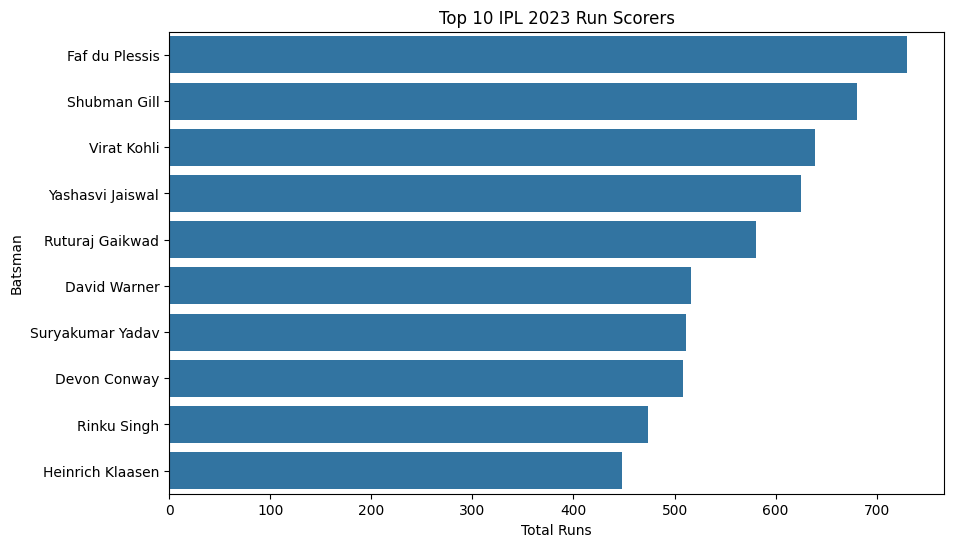

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_10,
    x="Run",
    y="Batsman"
)

plt.title("Top 10 IPL 2023 Run Scorers")
plt.xlabel("Total Runs")
plt.ylabel("Batsman")
plt.show()

In [ ]:
top_strike_rate = player_stats.sort_values(
    "Strike_Rate", ascending=False
).head(10)

top_strike_rate

,Batsman,Run,Ball,4s,6s,Strike_Rate
165,Vijaykumar Vyshak,13,3,0,1,433.333333
122,Rashid Khan,95,40,4,11,237.500000
160,Umran Malik,19,8,1,2,237.500000
88,Mark Wood,11,5,1,1,220.000000
9,Akash Deep,17,8,2,1,212.500000
35,David Wiese,21,11,0,3,190.909091
81,MS Dhoni,103,54,3,10,190.740741
151,Suryakumar Yadav,511,276,56,24,185.144928
45,Glenn Maxwell,400,218,29,31,183.486239
46,Glenn Phillips,39,22,2,4,177.272727


In [ ]:
qualified_players = player_stats[player_stats["Ball"] >= 100]

top_strike_rate = qualified_players.sort_values(
    "Strike_Rate", ascending=False
).head(10)

top_strike_rate

,Batsman,Run,Ball,4s,6s,Strike_Rate
151,Suryakumar Yadav,511,276,56,24,185.144928
45,Glenn Maxwell,400,218,29,31,183.486239
54,Heinrich Klaasen,448,253,32,25,177.075099
106,Nicholas Pooran,358,206,26,26,173.786408
8,Ajinkya Rahane,282,166,22,13,169.879518
62,Jitesh Sharma,280,166,16,21,168.674699
155,Tim David,216,130,11,15,166.153846
109,Philip Salt,218,133,24,10,163.909774
174,Yashasvi Jaiswal,625,382,83,26,163.612565
79,Liam Livingstone,279,171,20,19,163.157895


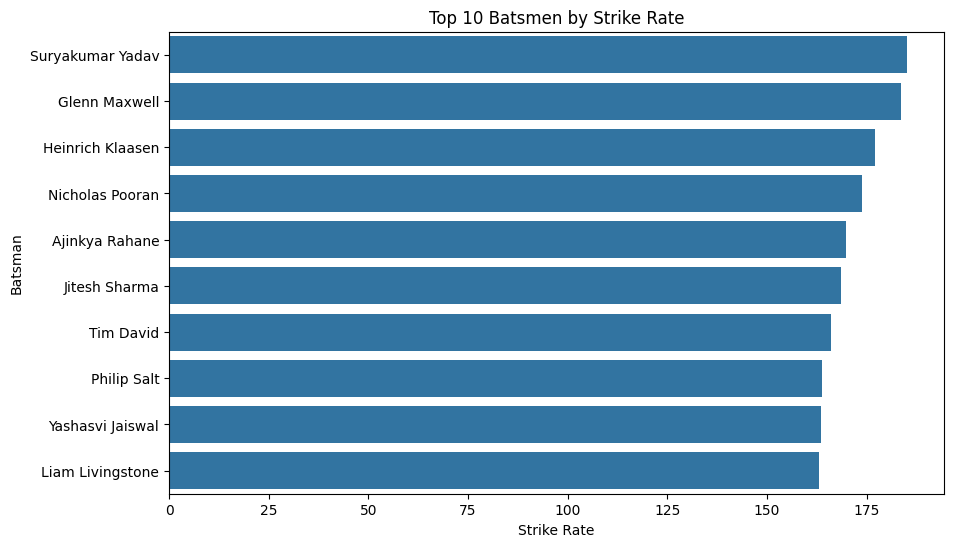

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_strike_rate,
    x="Strike_Rate",
    y="Batsman"
)

plt.title("Top 10 Batsmen by Strike Rate")
plt.xlabel("Strike Rate")
plt.ylabel("Batsman")
plt.show()

In [ ]:
top_six = player_stats.sort_values(
    "6s", ascending=False
).head(10)

top_six

,Batsman,Run,Ball,4s,6s,Strike_Rate
43,Faf du Plessis,730,475,60,36,153.684211
147,Shivam Dube,385,240,12,33,160.416667
45,Glenn Maxwell,400,218,29,31,183.486239
135,Ruturaj Gaikwad,581,397,48,29,146.347607
128,Rinku Singh,474,317,31,29,149.526814
106,Nicholas Pooran,358,206,26,26,173.786408
87,Marcus Stoinis,368,245,23,26,150.204082
174,Yashasvi Jaiswal,625,382,83,26,163.612565
54,Heinrich Klaasen,448,253,32,25,177.075099
139,Sanju Samson,362,236,25,24,153.389831


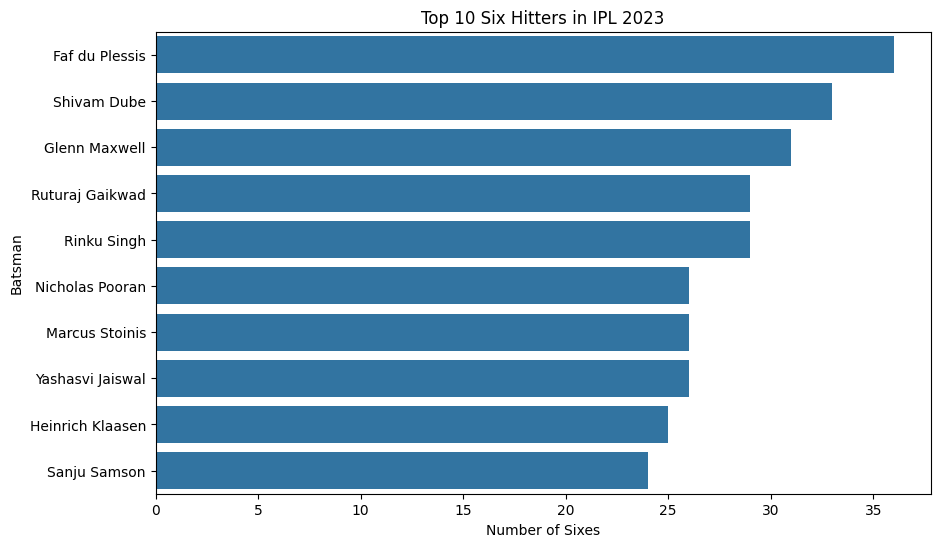

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_six,
    x="6s",
    y="Batsman"
)

plt.title("Top 10 Six Hitters in IPL 2023")
plt.xlabel("Number of Sixes")
plt.ylabel("Batsman")
plt.show()

In [ ]:
top_four = player_stats.sort_values(
    "4s", ascending=False
).head(10)

top_four

,Batsman,Run,Ball,4s,6s,Strike_Rate
174,Yashasvi Jaiswal,625,382,83,26,163.612565
34,David Warner,516,392,69,10,131.632653
148,Shubman Gill,680,446,67,22,152.466368
166,Virat Kohli,639,457,65,16,139.824945
43,Faf du Plessis,730,475,60,36,153.684211
40,Devon Conway,508,365,57,15,139.178082
151,Suryakumar Yadav,511,276,56,24,185.144928
56,Ishan Kishan,439,306,51,18,143.464052
145,Shikhar Dhawan,373,261,49,12,142.911877
135,Ruturaj Gaikwad,581,397,48,29,146.347607


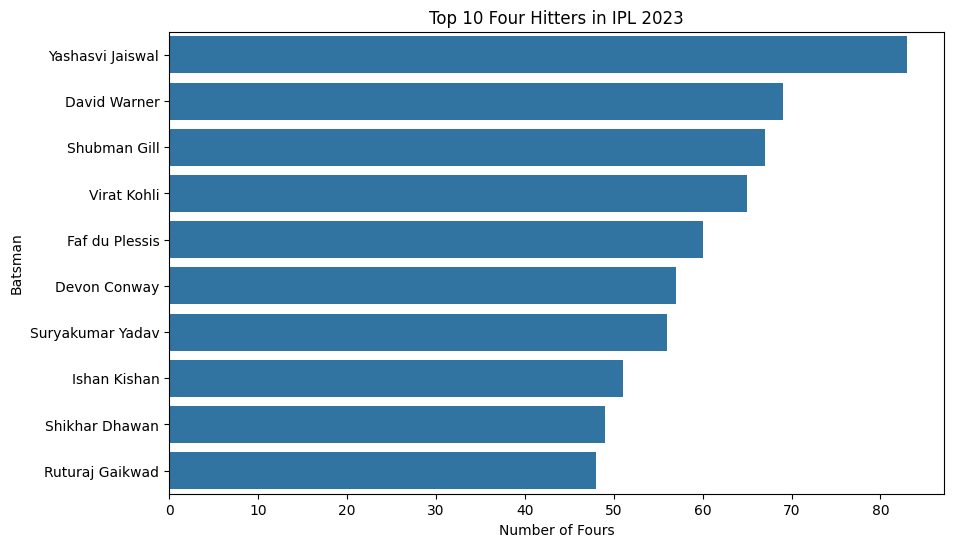

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_four,
    x="4s",
    y="Batsman"
)

plt.title("Top 10 Four Hitters in IPL 2023")
plt.xlabel("Number of Fours")
plt.ylabel("Batsman")
plt.show()

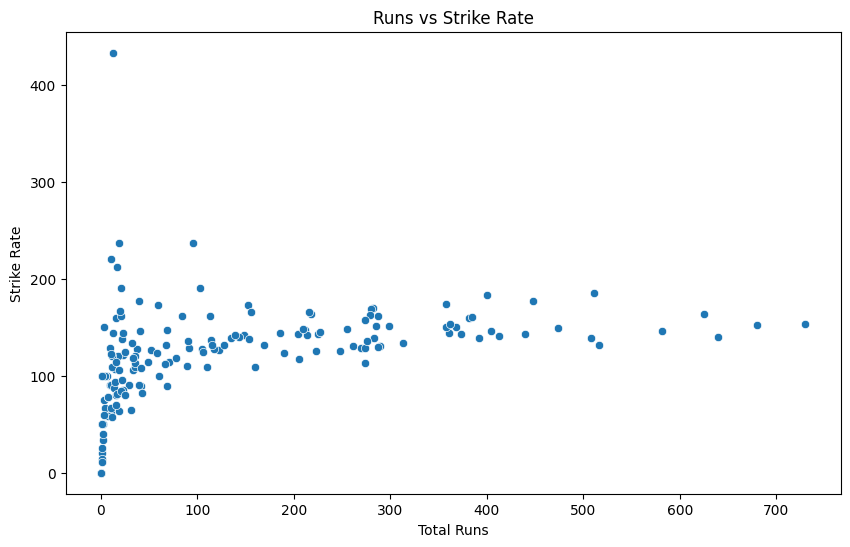

In [ ]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=player_stats,
    x="Run",
    y="Strike_Rate"
)

plt.title("Runs vs Strike Rate")
plt.xlabel("Total Runs")
plt.ylabel("Strike Rate")
plt.show()

In [ ]:
player_stats["Player_Rating"] = (
    (player_stats["Run"] * 0.5) +
    (player_stats["Strike_Rate"] * 0.3) +
    (player_stats["4s"] * 1) +
    (player_stats["6s"] * 2)
)

In [ ]:
player_stats["Player_Rating"] = player_stats["Player_Rating"].round(2)

In [ ]:
player_stats[
    ["Batsman", "Run", "Strike_Rate", "4s", "6s", "Player_Rating"]
].head(10)

,Batsman,Run,Strike_Rate,4s,6s,Player_Rating
0,Abdul Basith,1,100.000000,0,0,30.50
1,Abdul Samad,169,132.031250,10,11,156.11
2,Abhinav Manohar,114,137.349398,6,7,118.20
3,Abhishek Sharma,225,143.312102,28,6,195.49
4,Abishek Porel,33,106.451613,1,0,49.44
5,Adam Zampa,10,62.500000,0,0,23.75
6,Adil Rashid,22,137.500000,2,1,56.25
7,Aiden Markram,248,125.888325,18,8,195.77
8,Ajinkya Rahane,282,169.879518,22,13,239.96
9,Akash Deep,17,212.500000,2,1,76.25


In [ ]:
player_ranking = player_stats.sort_values(
    "Player_Rating",
    ascending=False
).reset_index(drop=True)

In [ ]:
player_ranking[
    ["Batsman", "Run", "Strike_Rate", "4s", "6s", "Player_Rating"]
].head(10)

,Batsman,Run,Strike_Rate,4s,6s,Player_Rating
0,Faf du Plessis,730,153.684211,60,36,543.11
1,Shubman Gill,680,152.466368,67,22,496.74
2,Yashasvi Jaiswal,625,163.612565,83,26,496.58
3,Virat Kohli,639,139.824945,65,16,458.45
4,Ruturaj Gaikwad,581,146.347607,48,29,440.40
5,Suryakumar Yadav,511,185.144928,56,24,415.04
6,David Warner,516,131.632653,69,10,386.49
7,Devon Conway,508,139.178082,57,15,382.75
8,Rinku Singh,474,149.526814,31,29,370.86
9,Heinrich Klaasen,448,177.075099,32,25,359.12


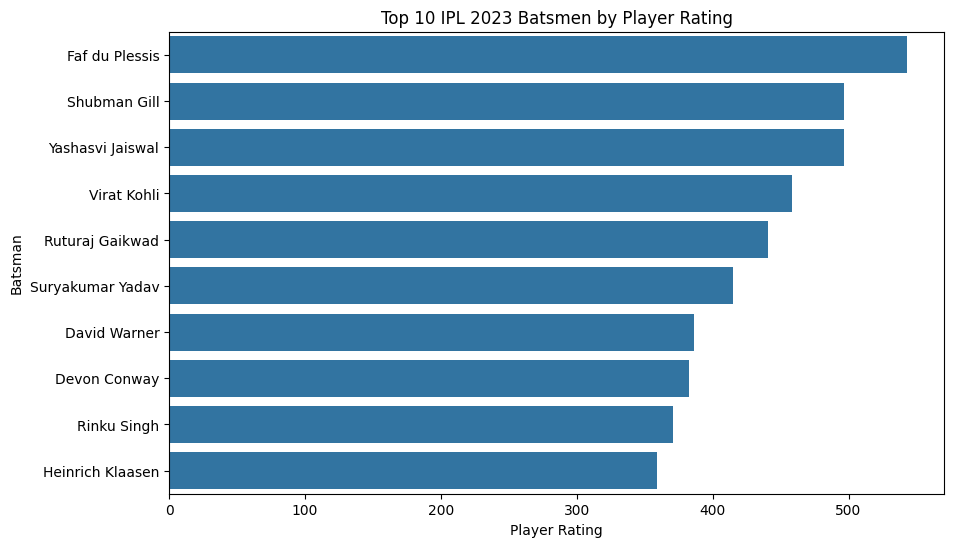

In [ ]:
top_rated = player_ranking.head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_rated,
    x="Player_Rating",
    y="Batsman"
)

plt.title("Top 10 IPL 2023 Batsmen by Player Rating")
plt.xlabel("Player Rating")
plt.ylabel("Batsman")
plt.show()

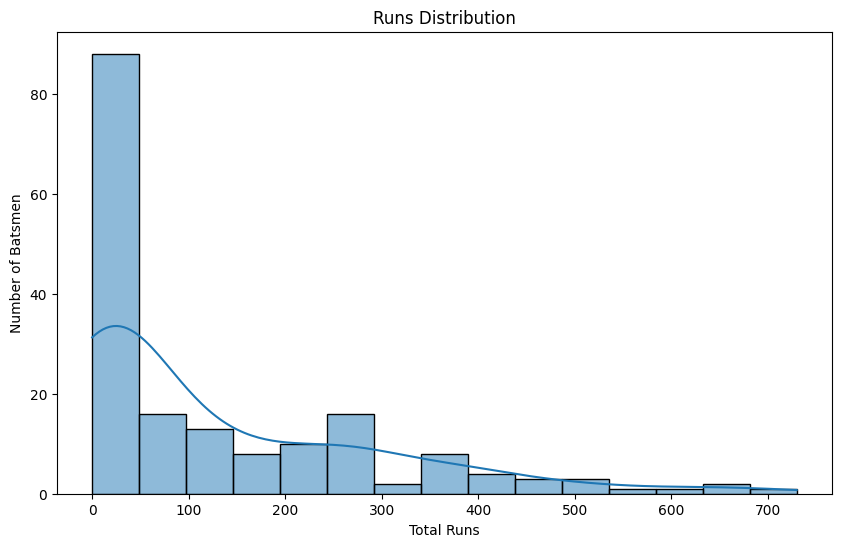

In [ ]:
plt.figure(figsize=(10, 6))

sns.histplot(
    player_stats["Run"],
    bins=15,
    kde=True
)

plt.title("Runs Distribution")
plt.xlabel("Total Runs")
plt.ylabel("Number of Batsmen")

plt.show()

In [ ]:
cluster_data = player_stats[
    ["Run", "Ball", "4s", "6s", "Strike_Rate"]
].copy()

In [ ]:
scaler = StandardScaler()

scaled_data = scaler.fit_transform(cluster_data)

In [ ]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

player_stats["Cluster"] = kmeans.fit_predict(scaled_data)

In [ ]:
player_stats[
    ["Batsman", "Run", "Strike_Rate", "4s", "6s", "Cluster"]
].head(20)

,Batsman,Run,Strike_Rate,4s,6s,Cluster
0,Abdul Basith,1,100.000000,0,0,0
1,Abdul Samad,169,132.031250,10,11,2
2,Abhinav Manohar,114,137.349398,6,7,2
3,Abhishek Sharma,225,143.312102,28,6,2
4,Abishek Porel,33,106.451613,1,0,0
5,Adam Zampa,10,62.500000,0,0,0
6,Adil Rashid,22,137.500000,2,1,0
7,Aiden Markram,248,125.888325,18,8,2
8,Ajinkya Rahane,282,169.879518,22,13,2
9,Akash Deep,17,212.500000,2,1,2


In [ ]:
cluster_summary = player_stats.groupby("Cluster")[
    ["Run", "Ball", "4s", "6s", "Strike_Rate"]
].mean()

cluster_summary

,Run,Ball,4s,6s,Strike_Rate
Cluster,,,,,
0,19.021739,18.902174,1.630435,0.413043,83.410811
1,459.125000,303.500000,43.083333,22.208333,152.522195
2,172.133333,121.583333,14.566667,8.150000,154.170703


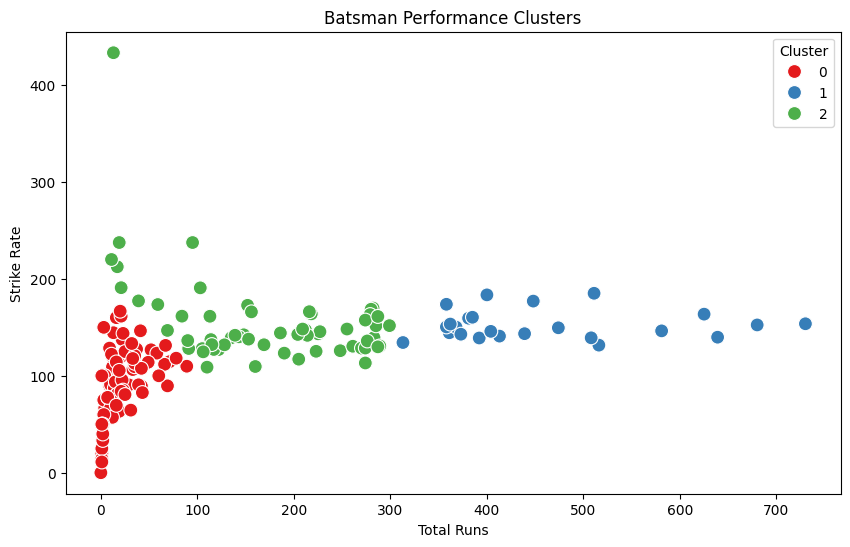

In [ ]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=player_stats,
    x="Run",
    y="Strike_Rate",
    hue="Cluster",
    palette="Set1",
    s=100
)

plt.title("Batsman Performance Clusters")
plt.xlabel("Total Runs")
plt.ylabel("Strike Rate")
plt.legend(title="Cluster")
plt.show()

In [ ]:
player_stats["Cluster"].value_counts().sort_index()

,count
Cluster,
0,92
1,24
2,60


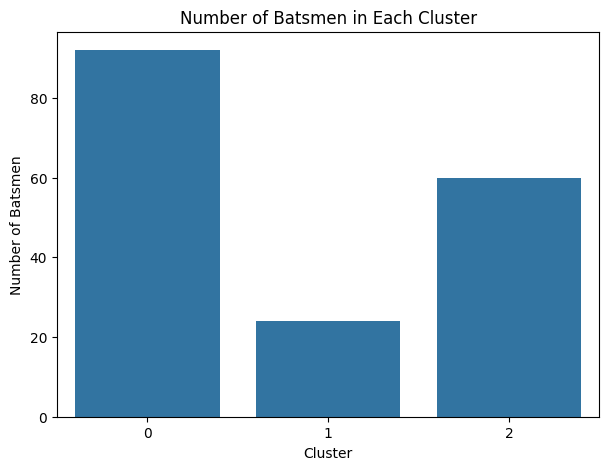

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=player_stats,
    x="Cluster"
)

plt.title("Number of Batsmen in Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Batsmen")
plt.show()

In [ ]:
for cluster in sorted(player_stats["Cluster"].unique()):
    print("\nCluster:", cluster)

    print(
        player_stats[
            player_stats["Cluster"] == cluster
        ][["Batsman", "Run", "Strike_Rate", "4s", "6s"]]
        .sort_values("Run", ascending=False)
        .head(5)
    )


Cluster: 0
                 Batsman  Run  Strike_Rate  4s  6s
102         N Jagadeesan   89   109.876543  14   1
131          Riyan Parag   78   118.181818   4   5
28     Bhanuka Rajapaksa   71   114.516129   6   2
38          Deepak Hooda   69    89.610390   3   1
124  Ravichandran Ashwin   67   131.372549   5   3

Cluster: 1
              Batsman  Run  Strike_Rate  4s  6s
43     Faf du Plessis  730   153.684211  60  36
148      Shubman Gill  680   152.466368  67  22
166       Virat Kohli  639   139.824945  65  16
174  Yashasvi Jaiswal  625   163.612565  83  26
135   Ruturaj Gaikwad  581   146.347607  48  29

Cluster: 2
             Batsman  Run  Strike_Rate  4s  6s
146  Shimron Hetmyer  299   151.776650  12  23
47     Hardik Pandya  289   130.769231  23  11
172  Wriddhiman Saha  287   129.864253  37   7
164    Vijay Shankar  287   161.235955  27  14
60         Jason Roy  285   151.595745  36  12


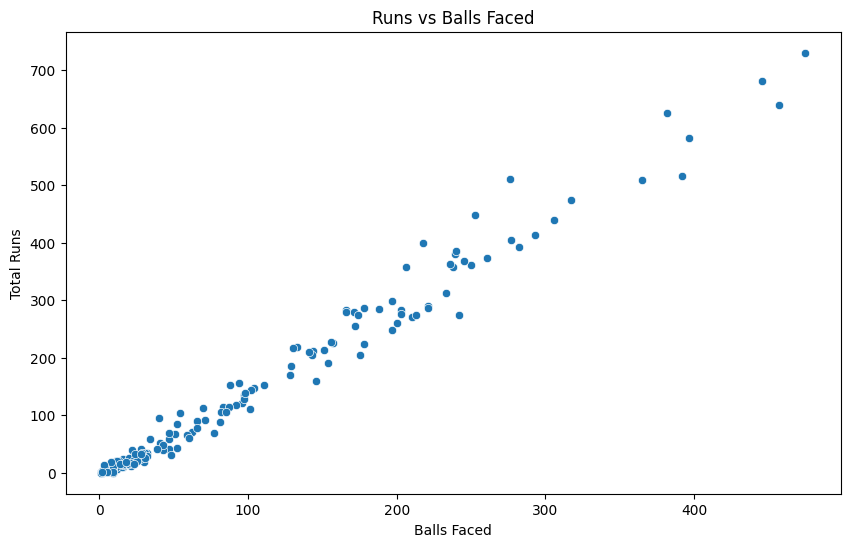

In [ ]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=player_stats,
    x="Ball",
    y="Run"
)

plt.title("Runs vs Balls Faced")
plt.xlabel("Balls Faced")
plt.ylabel("Total Runs")

plt.show()

In [ ]:
team_runs = df.groupby("team")["Run"].sum().sort_values(
    ascending=False
)

# Display team-wise runs
print("\nTeam-wise Total Runs:")
print(team_runs)

# Convert to DataFrame (useful for visualization)
team_runs_df = team_runs.reset_index()

# Display table
team_runs_df


Team-wise Total Runs:
team
Mumbai Indians                 2491
Punjab Kings                   2416
Royal Challengers Bangalore    2401
Kolkata Knight Riders          2338
Gujarat Titans                 2331
Rajasthan Royals               2287
Sunrisers Hyderabad            2268
Chennai Super Kings            2267
Lucknow Super Giants           2235
Delhi Capitals                 2063
Name: Run, dtype: int64


,team,Run
0,Mumbai Indians,2491
1,Punjab Kings,2416
2,Royal Challengers Bangalore,2401
3,Kolkata Knight Riders,2338
4,Gujarat Titans,2331
5,Rajasthan Royals,2287
6,Sunrisers Hyderabad,2268
7,Chennai Super Kings,2267
8,Lucknow Super Giants,2235
9,Delhi Capitals,2063


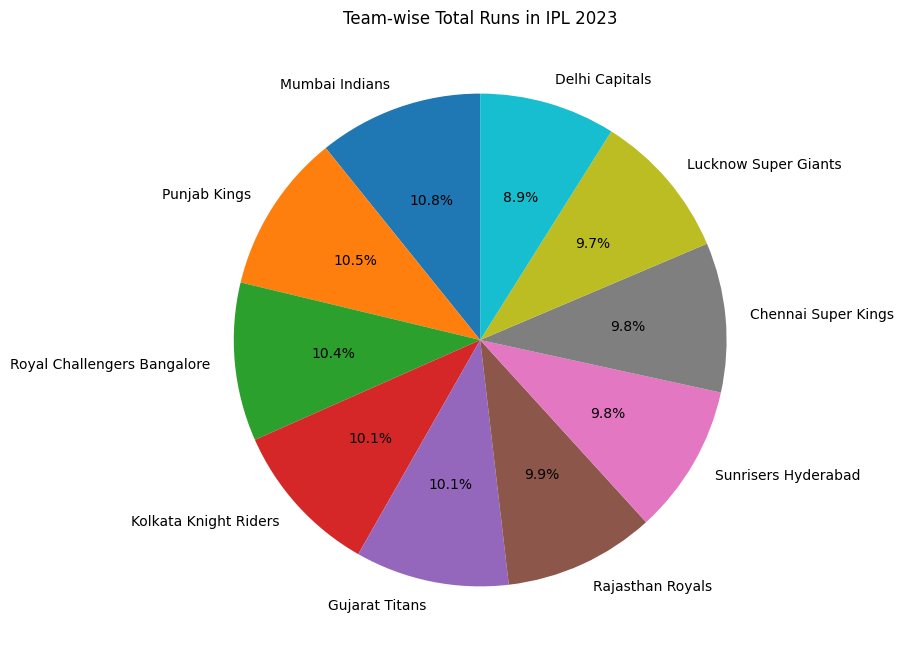

In [ ]:
plt.figure(figsize=(10, 8))

plt.pie(
    team_runs,
    labels=team_runs.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Team-wise Total Runs in IPL 2023")

plt.show()

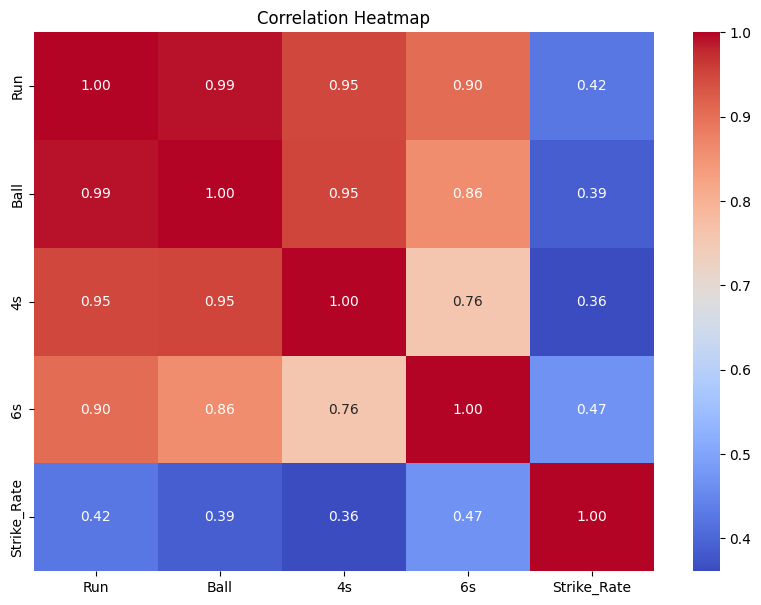

In [ ]:
plt.figure(figsize=(10, 7))

correlation = player_stats[
    ["Run", "Ball", "4s", "6s", "Strike_Rate"]
].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()